In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("StressLevelDataset.csv")
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (1100, 21)
   anxiety_level  self_esteem  mental_health_history  depression  headache  \
0             14           20                      0          11         2   
1             15            8                      1          15         5   
2             12           18                      1          14         2   
3             16           12                      1          15         4   
4             16           28                      0           7         2   

   blood_pressure  sleep_quality  breathing_problem  noise_level  \
0               1              2                  4            2   
1               3              1                  4            3   
2               1              2                  2            2   
3               3              1                  3            4   
4               3              5                  1            3   

   living_conditions  ...  basic_needs  academic_performance  study_load  \
0                  3

In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    1100 non-null 

In [6]:
df.describe()

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,...,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,11.063636,17.777273,0.492727,12.555455,2.508182,2.181818,2.660000,2.753636,2.649091,2.518182,...,2.772727,2.772727,2.621818,2.648182,2.649091,1.881818,2.734545,2.767273,2.617273,0.996364
std,6.117558,8.944599,0.500175,7.727008,1.409356,0.833575,1.548383,1.400713,1.328127,1.119208,...,1.433761,1.414594,1.315781,1.384579,1.529375,1.047826,1.425265,1.417562,1.530958,0.821673
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,11.000000,0.000000,6.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,2.000000,2.000000,1.000000,0.000000
50%,11.000000,19.000000,0.000000,12.000000,3.000000,2.000000,2.500000,3.000000,3.000000,2.000000,...,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.500000,3.000000,1.000000
75%,16.000000,26.000000,1.000000,19.000000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,...,4.000000,4.000000,3.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,2.000000
max,21.000000,30.000000,1.000000,27.000000,5.000000,3.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,3.000000,5.000000,5.000000,5.000000,2.000000


In [7]:
print(df.isnull().sum())
print(df["stress_level"].value_counts())

anxiety_level                   0
self_esteem                     0
mental_health_history           0
depression                      0
headache                        0
blood_pressure                  0
sleep_quality                   0
breathing_problem               0
noise_level                     0
living_conditions               0
safety                          0
basic_needs                     0
academic_performance            0
study_load                      0
teacher_student_relationship    0
future_career_concerns          0
social_support                  0
peer_pressure                   0
extracurricular_activities      0
bullying                        0
stress_level                    0
dtype: int64
stress_level
0    373
2    369
1    358
Name: count, dtype: int64


In [8]:
df = df.copy()

In [9]:
df.columns = df.columns.str.strip()

In [10]:
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Text columns:", text_cols)

Text columns: []


In [11]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [15]:
ranges = pd.DataFrame({
    "Min": df.min(),
    "Max": df.max(),
    "Unique Values": df.nunique()
})
print(ranges)

                              Min  Max  Unique Values
anxiety_level                   0   21             22
self_esteem                     0   30             31
mental_health_history           0    1              2
depression                      0   27             28
headache                        0    5              6
blood_pressure                  1    3              3
sleep_quality                   0    5              6
breathing_problem               0    5              6
noise_level                     0    5              6
living_conditions               0    5              6
safety                          0    5              6
basic_needs                     0    5              6
academic_performance            0    5              6
study_load                      0    5              6
teacher_student_relationship    0    5              6
future_career_concerns          0    5              6
social_support                  0    3              4
peer_pressure               

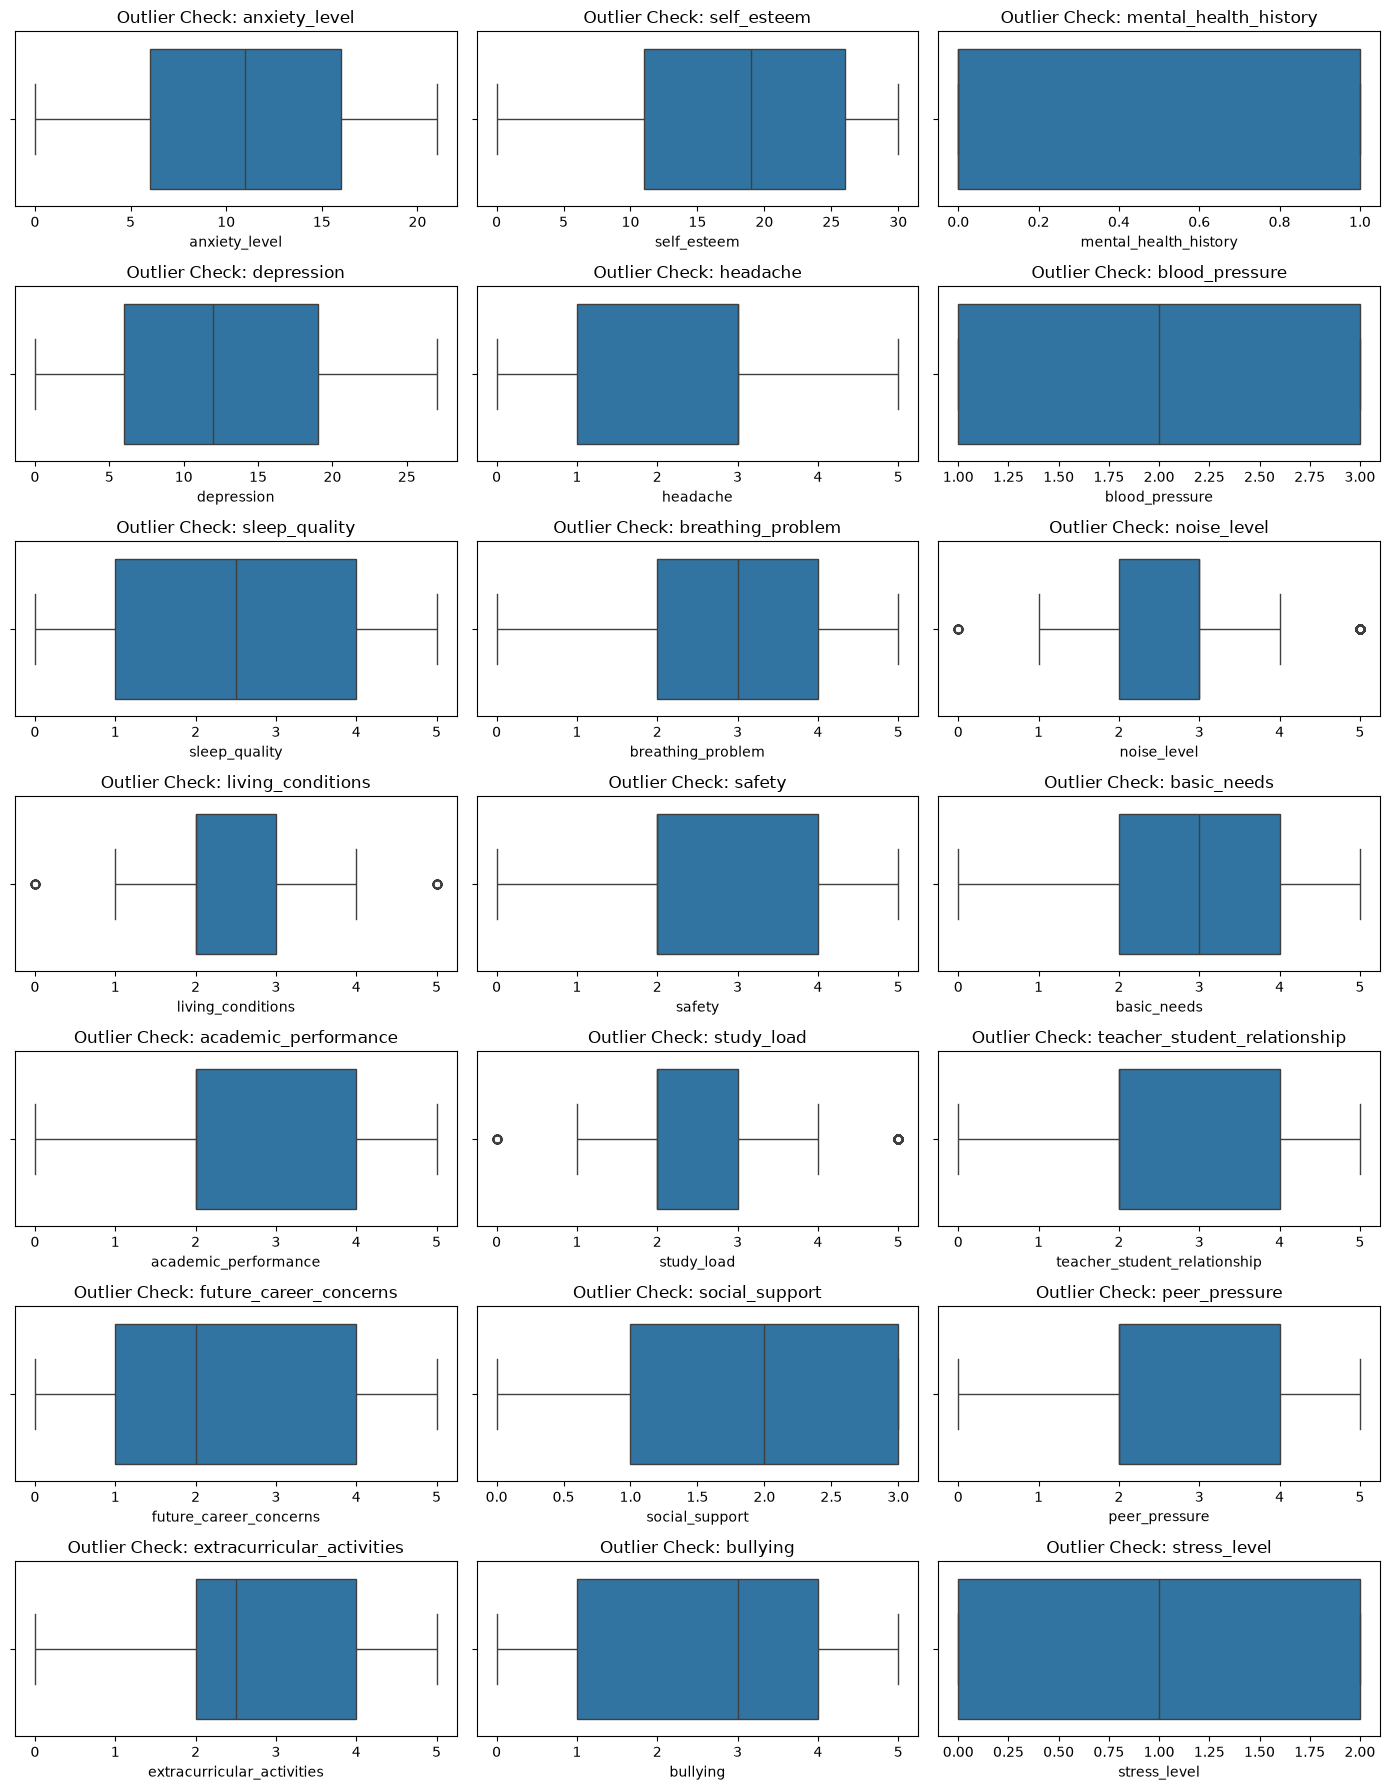

In [16]:
num_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
fig, axes = plt.subplots(7, 3, figsize=(14, 18))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title("Outlier Check: " + col)
plt.tight_layout()
plt.show()

In [17]:
outlier_results = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()
    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Flagged Values": int(count)
    })
outlier_df = pd.DataFrame(outlier_results)
print(outlier_df[outlier_df["Flagged Values"] > 0].to_string(index=False))

           Column  Lower Bound  Upper Bound  Flagged Values
      noise_level          0.5          4.5             173
living_conditions          0.5          4.5              62
       study_load          0.5          4.5             165


only noise_level, study_load and living_conditions are flagged. These are answers on a 0 to 5 scale, so the flagged values are valid survey answers and not errors. No rows were removed.

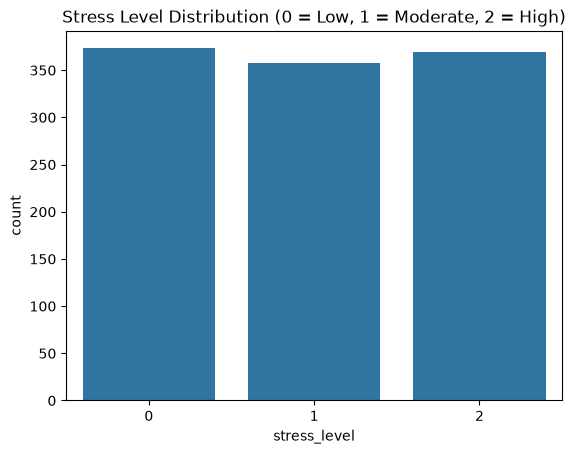

In [18]:
sns.countplot(x="stress_level", data=df)
plt.title("Stress Level Distribution (0 = Low, 1 = Moderate, 2 = High)")
plt.show()

In [19]:
print((df["stress_level"].value_counts(normalize=True) * 100).round(2))

stress_level
0    33.91
2    33.55
1    32.55
Name: proportion, dtype: float64


In [ ]:
corr = df.corr()["stress_level"].drop("stress_level").sort_values()
plt.figure(figsize=(8, 7))
sns.barplot(x=corr.values, y=corr.index, palette="coolwarm")
plt.title("Correlation of Each Feature with Stress Level")
plt.xlabel("Correlation")
plt.show()

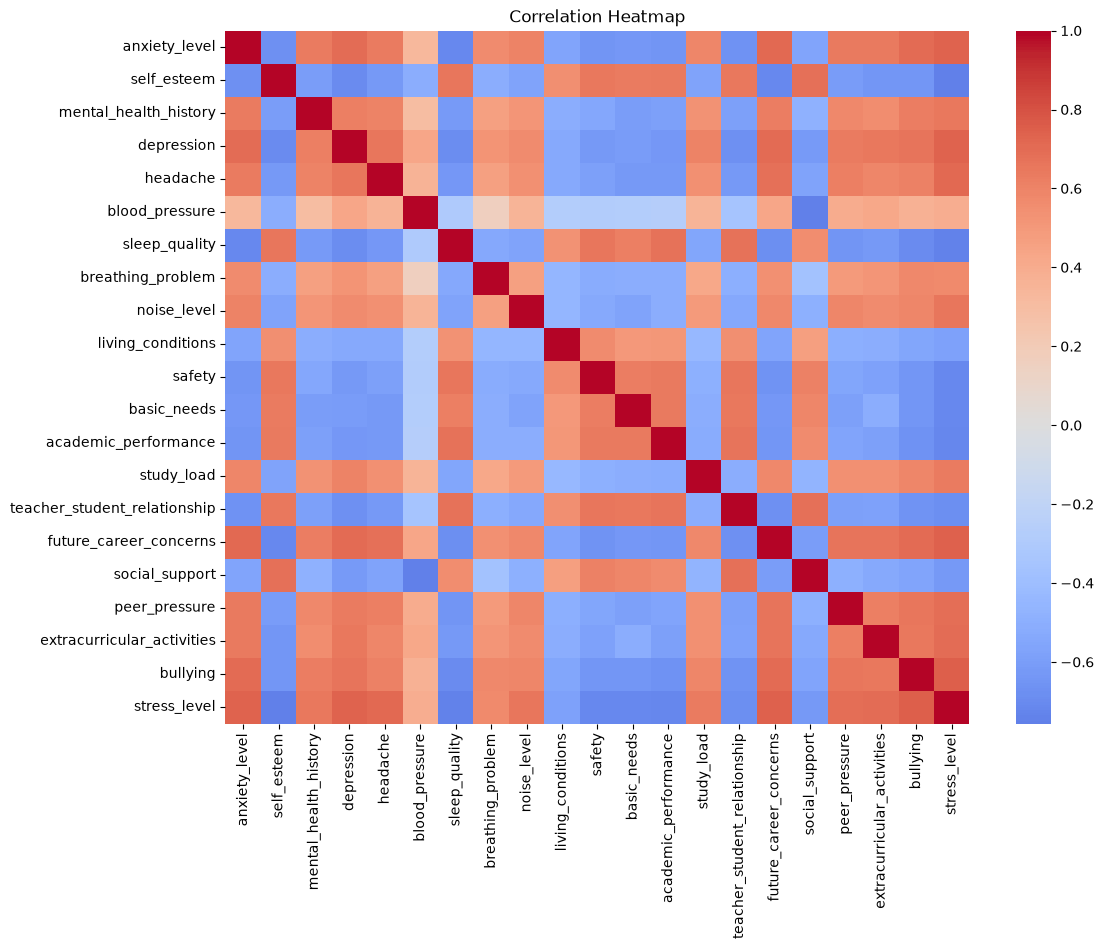

In [21]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()